# The scorecard idea: weight of evidence, information value and points

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (getting started)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the weight of evidence (WoE) and the information value (IV) of a binned variable measure, and recompute both from the counts of a bin;
- explain how a logistic model on WoE becomes a table of points, and what "points to double the odds" (PDO) means;
- recompute the score of a card from its points alone, without the model, and show what the rounding of the points costs;
- read the discrimination and the grade table of the scorecard on the 9,000 held-out cards.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C01 (retail credit-card PD) as Contraste commits it. The 30,000 cards come from the UCI Taiwan credit-card file (Yeh, 2009; CC BY 4.0, licence class `mirror-allowed`, https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). The pipeline split them once, with a fixed seed: 16,800 cards to fit the scorecard, 4,200 to calibrate the challengers, and a locked holdout of 9,000 cards that no fit has seen. Two committed files hold everything this notebook needs, so it fits nothing and needs no raw data:

- `data/derived/C01/models-taiwan.json`: the fitted scorecard (rung P1): its coefficients, its information values and its table of points with the counts of every bin on the 16,800 training cards. Owner: this repository.
- `data/derived/C01/holdout.json`: the scorecard on the holdout: a sample of 50 cards with their raw inputs, their points, their score and their PD, the 12 grades of the master scale, and the committed test rows.

The next cell loads both files and prints what the scorecard holds.

In [2]:
# Load the two committed files (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C01"
models = json.loads((derived / "models-taiwan.json").read_text(encoding="utf-8"))
holdout = json.loads((derived / "holdout.json").read_text(encoding="utf-8"))

# The scorecard is the model whose id is P1-scorecard
card = next(m for m in models["model"] if m["id"] == "P1-scorecard")["details"]
table = card["points_table"]
print("fitted on", models["fit"]["train_rows"], "training cards, with", models["fit"]["split"]["train"]["defaults"], "defaults")
print("variables kept:", len(card["features"]), "| variables dropped:", len(card["dropped"]))
print("rows of the points table:", len(table))
print("scaling:", {k: round(v, 4) for k, v in card["scaling"].items()})
print("baked by riskvalidation", models["provenance"]["riskvalidation_version"], "| installed", rv.__version__)


fitted on 16800 training cards, with 3716 defaults
variables kept: 13 | variables dropped: 7
rows of the points table: 95
scaling: {'pdo': 20.0, 'odds_ref': 50.0, 'score_ref': 600.0, 'factor': 28.8539, 'offset': 487.1229}
baked by riskvalidation 0.4.3 | installed 0.9.0


## Method

### Step 1: a variable in bins

A scorecard does not use a raw variable. It cuts each one into a few ordered **bins** (optimal binning with a monotone trend: the default rate must rise, or fall, along the bins, and no bin may hold less than 5% of the cards) and works with the bin a card falls in. The reason is practical: a bin is a row of a printed table that a credit officer can read and an auditor can check. The variable with the strongest signal is `PAY_0`, the repayment status of the latest month (-1 paid duly, 1 one month late, 2 two months late, and so on). The next cell prints its bins as the points table commits them: the cards in each bin on the training slice, the defaults among them and the default rate. The last two rows, `Special` and `Missing`, are the bins for special codes and missing values; no training card falls in them.

In [3]:
# The bins of PAY_0 as committed: cards, defaults and default rate
pay0 = [row for row in table if row["feature"] == "PAY_0"]
print(f"{'bin':>16s} {'cards':>7s} {'defaults':>9s} {'rate':>7s}")
for row in pay0:
    rate = "-" if row["event_rate"] is None else f"{row['event_rate']:.4f}"
    print(f"{row['bin']:>16s} {row['count']:7d} {row['events']:9d} {rate:>7s}")
print("total cards:", sum(r["count"] for r in pay0), "| total defaults:", sum(r["events"] for r in pay0))


             bin   cards  defaults    rate
   (-inf, -1.50)    1562       204  0.1306
   [-1.50, 0.50)   11339      1554  0.1370
    [0.50, 1.50)    2112       713  0.3376
     [1.50, inf)    1787      1245  0.6967
         Special       0         0       -
         Missing       0         0       -
total cards: 16800 | total defaults: 3716


### Step 2: weight of evidence

For a binary target ($E$ = event, here a default; $NE$ = non-event) and bin $i$, the weight of evidence compares the share of all non-events that fall in the bin with the share of all events that fall in it (Navas-Palencia, 2020, section 2.1):

$$\mathrm{WoE}_i = \ln\!\left(\frac{r_i^{NE} / r_T^{NE}}{r_i^{E} / r_T^{E}}\right)$$

where $r_i^{NE}$ and $r_i^{E}$ are the non-events and events in the bin and $r_T^{NE}$, $r_T^{E}$ the totals. With this sign, a higher WoE means a **lower** risk: a bin that holds more good cards than bad ones has a positive WoE. The same source shows that WoE is an affine, decreasing function of the bin's log-odds of default, which is why it linearises the problem for a logistic model. The next cell recomputes the WoE of every bin of `PAY_0` from its counts and compares it with the committed value. This is a check of the definition on the counts, not a second implementation of the fit: the binning and the fit remain the pipeline's.

In [4]:
# Recompute the WoE of each PAY_0 bin from its counts and compare it with the committed value
total_events = sum(r["events"] for r in pay0)
total_non_events = sum(r["count"] - r["events"] for r in pay0)
print("totals: events", total_events, "| non-events", total_non_events)
print(f"{'bin':>16s} {'share of non-events':>22s} {'share of events':>20s} {'WoE':>8s} {'committed':>10s}")
gap_max = 0.0
for row in pay0:
    if row["count"] == 0:
        continue
    p_non_event = (row["count"] - row["events"]) / total_non_events
    q_event = row["events"] / total_events
    woe = float(np.log(p_non_event / q_event))
    gap_max = max(gap_max, abs(woe - row["woe"]))
    print(f"{row['bin']:>16s} {p_non_event:22.5f} {q_event:20.5f} {woe:8.4f} {row['woe']:10.4f}")
print("largest difference with the committed WoE:", f"{gap_max:.2e}")


totals: events 3716 | non-events 13084
             bin    share of non-events      share of events      WoE  committed
   (-inf, -1.50)                0.10379              0.05490   0.6369     0.6369
   [-1.50, 0.50)                0.74786              0.41819   0.5813     0.5813
    [0.50, 1.50)                0.10692              0.19187  -0.5847    -0.5847
     [1.50, inf)                0.04142              0.33504  -2.0904    -2.0904
largest difference with the committed WoE: 1.11e-16


### Step 3: information value

The information value adds up, over the bins, how far apart the two shares are, weighted by the WoE. It is the symmetrised Kullback-Leibler divergence (Jeffreys' divergence) between the distribution of the non-events and the distribution of the events over the bins:

$$\mathrm{IV} = \sum_{i=1}^{n} (p_i - q_i)\,\mathrm{WoE}_i, \qquad p_i = \frac{r_i^{NE}}{r_T^{NE}},\; q_i = \frac{r_i^{E}}{r_T^{E}}$$

An IV of 0 means the variable does not separate defaulters from the rest at all. The pipeline keeps a variable only if its IV is at least 0.02, a convention attributed to Siddiqi (2017) whose book page the research could not verify; it is a screening rule, not a theorem. The next cell recomputes the IV of `PAY_0` from the bin shares and compares it with the committed total and with the committed IV of each bin.

In [5]:
# Recompute the information value of PAY_0 from the bin shares and compare it with the committed values
iv_total = 0.0
for row in pay0:
    if row["count"] == 0:
        continue
    p_non_event = (row["count"] - row["events"]) / total_non_events
    q_event = row["events"] / total_events
    contribution = (p_non_event - q_event) * float(np.log(p_non_event / q_event))
    iv_total += contribution
    print(f"{row['bin']:>16s} IV of the bin {contribution:.5f} | committed {row['iv']:.5f}")
print("IV of PAY_0 from the counts:", round(iv_total, 6), "| committed:", round(card["iv"]["PAY_0"], 6))


   (-inf, -1.50) IV of the bin 0.03114 | committed 0.03114
   [-1.50, 0.50) IV of the bin 0.19163 | committed 0.19163
    [0.50, 1.50) IV of the bin 0.04967 | committed 0.04967
     [1.50, inf) IV of the bin 0.61376 | committed 0.61376
IV of PAY_0 from the counts: 0.886198 | committed: 0.886198


The pipeline computes the IV of every variable on the training slice and keeps those at or above 0.02. The next cell lists all 20 variables with their IV, marks the ones the scorecard kept and gives the reason for each one it dropped. The figure beside it draws the same numbers.

In [6]:
# List the information value of every variable, kept or dropped
ranked = sorted(card["iv"].items(), key=lambda item: -item[1])
for name, value in ranked:
    status = "kept" if name in card["features"] else "dropped: below the threshold"
    print(f"{name:10s} IV {value:7.4f}  {status}")


PAY_0      IV  0.8862  kept
PAY_2      IV  0.5618  kept
PAY_3      IV  0.4133  kept
PAY_4      IV  0.3504  kept
PAY_5      IV  0.3401  kept
PAY_6      IV  0.2944  kept
LIMIT_BAL  IV  0.1920  kept
PAY_AMT1   IV  0.1813  kept
PAY_AMT2   IV  0.1759  kept
PAY_AMT3   IV  0.1410  kept
PAY_AMT4   IV  0.1090  kept
PAY_AMT6   IV  0.1030  kept
PAY_AMT5   IV  0.1007  kept
EDUCATION  IV  0.0189  dropped: below the threshold
BILL_AMT1  IV  0.0105  dropped: below the threshold
BILL_AMT2  IV  0.0079  dropped: below the threshold
BILL_AMT3  IV  0.0069  dropped: below the threshold
BILL_AMT4  IV  0.0062  dropped: below the threshold
BILL_AMT6  IV  0.0040  dropped: below the threshold
BILL_AMT5  IV  0.0025  dropped: below the threshold


The figure draws the same numbers: the information value of each variable against the 0.02 threshold, blue for the variables kept and grey for the ones dropped.

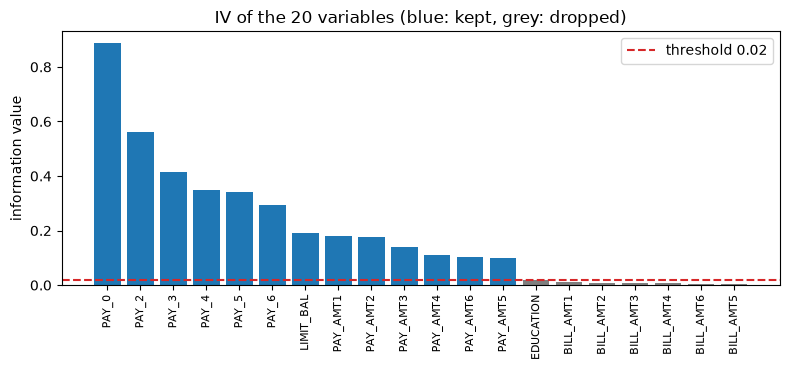

In [7]:
# Draw the information value of every variable against the 0.02 screening threshold
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [n for n, _ in ranked]
values = [v for _, v in ranked]
colors = ["tab:blue" if n in card["features"] else "tab:gray" for n in names]
ax.bar(range(len(names)), values, color=colors)
ax.axhline(0.02, color="tab:red", linestyle="--", label="threshold 0.02")
ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_ylabel("information value")
ax.set_title("IV of the 20 variables (blue: kept, grey: dropped)")
ax.legend()
fig.tight_layout()
plt.show()


### Step 4: a logistic model on the WoE

Each kept variable enters the model through its WoE, so the model is linear in the evidence of the bins. With $k$ variables, $\mathrm{WoE}_j(x_j)$ the WoE of the bin of variable $j$ in which the card falls, and $\eta$ the log-odds **of the event** in the sign convention of the pipeline's dossier:

$$\eta(x) = \beta_0 + \sum_{j=1}^{k} \beta_j\,\mathrm{WoE}_j(x_j), \qquad \mathrm{PD}(x) = \frac{1}{1 + e^{-\eta(x)}}$$

Because a higher WoE means a lower risk, every coefficient of a sound scorecard is **negative**: a card in a better bin must get a lower $\eta$. A positive coefficient is a warning that two variables carry the same signal and fight over it (the pipeline drops the wrong-signed variable with the largest p-value and refits). The next cell prints the intercept and the 13 coefficients and checks the signs.

In [8]:
# Print the intercept and the coefficients and check that every coefficient is negative
print("intercept beta_0:", round(card["intercept"], 4))
for name in card["features"]:
    print(f"{name:10s} beta {card['coefficients'][name]:8.4f}")
print("all coefficients negative:", all(b < 0 for b in card["coefficients"].values()))


intercept beta_0: -1.2517
LIMIT_BAL  beta  -0.3135
PAY_0      beta  -0.7435
PAY_2      beta  -0.0786
PAY_3      beta  -0.1533
PAY_4      beta  -0.0958
PAY_5      beta  -0.1925
PAY_6      beta  -0.2195
PAY_AMT1   beta  -0.1378
PAY_AMT2   beta  -0.2768
PAY_AMT3   beta  -0.2639
PAY_AMT4   beta  -0.1114
PAY_AMT5   beta  -0.0840
PAY_AMT6   beta  -0.1704
all coefficients negative: True


### Step 5: the scale of the points

A model that outputs a log-odds is hard to use at a desk. A scorecard turns it into a score that is linear in the log-odds of being **good**, and fixes the scale with three numbers (Siddiqi, 2017; the formula as ING's open `skorecard` implements it):

$$\mathrm{Score} = \mathrm{Offset} + \mathrm{Factor}\cdot\ln(\mathrm{odds}_{good}), \qquad \mathrm{Factor} = \frac{\mathrm{PDO}}{\ln 2}, \qquad \mathrm{Offset} = \mathrm{Score}_{ref} - \mathrm{Factor}\cdot\ln(\mathrm{odds}_{ref})$$

The **points to double the odds** (PDO) is the number of points that doubles the odds of being good: with a PDO of 20, a card 20 points higher has twice the odds of being good. This scorecard sets PDO = 20, a reference score of 600 at reference odds of 50 to 1. The next cell recomputes the Factor and the Offset and compares them with the committed scaling.

In [9]:
# Recompute the Factor and the Offset from the three scale numbers
pdo, odds_ref, score_ref = 20.0, 50.0, 600.0
factor = pdo / np.log(2.0)
offset = score_ref - factor * np.log(odds_ref)
print("PDO:", pdo, "| odds_ref:", odds_ref, "| score_ref:", score_ref)
print("Factor:", round(float(factor), 6), "| committed:", round(card["scaling"]["factor"], 6))
print("Offset:", round(float(offset), 6), "| committed:", round(card["scaling"]["offset"], 6))


PDO: 20.0 | odds_ref: 50.0 | score_ref: 600.0
Factor: 28.853901 | committed: 28.853901
Offset: 487.122876 | committed: 487.122876


### Step 6: the points of a bin

The total score must equal $\mathrm{Offset} - \mathrm{Factor}\cdot\eta$ (the minus sign is the pipeline's WoE convention: a higher $\eta$ is a riskier card, so it must lose points). To obtain it as a **sum of per-bin points**, the offset and the intercept are shared out evenly among the $k$ variables (the `skorecard` formula):

$$\mathrm{Points}_{j,b} = \frac{\mathrm{Offset}}{k} - \left(\beta_j\,\mathrm{WoE}_{j,b} + \frac{\beta_0}{k}\right)\mathrm{Factor}$$

Summing over the $k$ variables gives $\mathrm{Offset} - \mathrm{Factor}\,\eta$ exactly. The points are then **rounded to integers**, because a scorecard is a printed table. The next cell recomputes the unrounded points of every row of the committed table from its WoE and the coefficients, compares them, rounds them, and prints two variables as a card holder would see them.

In [10]:
# Recompute the points of every row of the table from its WoE and the coefficients, then round them
k = len(card["features"])
beta_0 = card["intercept"]
raw_gap, round_gap = 0.0, 0
for row in table:
    beta = card["coefficients"][row["feature"]]
    points_raw = offset / k - (beta * row["woe"] + beta_0 / k) * factor
    raw_gap = max(raw_gap, abs(points_raw - row["points_raw"]))
    round_gap = max(round_gap, abs(int(round(points_raw)) - row["points"]))
print("rows checked:", len(table), "| variables k:", k)
print("largest difference of the unrounded points:", f"{raw_gap:.2e}")
print("largest difference of the rounded points (in points):", round_gap)
for feature in ("PAY_0", "LIMIT_BAL"):
    print()
    print(feature)
    for row in table:
        if row["feature"] == feature and row["count"] > 0:
            print(f"  {row['bin']:>26s}  WoE {row['woe']:7.3f}  points {row['points_raw']:7.2f} -> {row['points']:3d}")


rows checked: 95 | variables k: 13
largest difference of the unrounded points: 0.00e+00
largest difference of the rounded points (in points): 0

PAY_0
               (-inf, -1.50)  WoE   0.637  points   53.91 ->  54
               [-1.50, 0.50)  WoE   0.581  points   52.72 ->  53
                [0.50, 1.50)  WoE  -0.585  points   27.70 ->  28
                 [1.50, inf)  WoE  -2.090  points   -4.60 ->  -5

LIMIT_BAL
            (-inf, 45000.00)  WoE  -0.717  points   33.77 ->  34
        [45000.00, 75000.00)  WoE  -0.241  points   38.07 ->  38
       [75000.00, 105000.00)  WoE  -0.119  points   39.18 ->  39
      [105000.00, 145000.00)  WoE  -0.078  points   39.54 ->  40
      [145000.00, 165000.00)  WoE   0.226  points   42.29 ->  42
      [165000.00, 245000.00)  WoE   0.301  points   42.97 ->  43
      [245000.00, 375000.00)  WoE   0.524  points   44.99 ->  45
            [375000.00, inf)  WoE   0.771  points   47.22 ->  47


### Step 7: the score of a card is a sum

To score a card, find its bin in each of the 13 variables and add the points. The holdout artifact keeps 50 cards with their 13 point columns and the score the pipeline gave them, so the claim can be checked: the score must be the sum of the points, and nothing else. The next cell sums the points of the 50 cards, compares with the committed score, and prints the first three cards with their points by variable.

In [11]:
# Add the 13 point columns of the 50 sample cards and compare the sum with the committed score
sample = holdout["outputs"]["sample"]
y = np.array(sample["targets"])
points = np.array(sample["scorecard_points"])
score = np.array(sample["scorecard_score"])
print("cards:", points.shape[0], "| point columns:", points.shape[1])
print("the score is the sum of the points for every card:", bool((points.sum(axis=1) == score).all()))
print(f"{'':8s}" + "".join(f"{name.replace('PAY_AMT', 'AMT').replace('LIMIT_BAL', 'LIMIT'):>8s}" for name in card["features"]) + f"{'score':>8s}")
for i in range(3):
    print(f"{sample['ids'][i]:8s}" + "".join(f"{int(p):8d}" for p in points[i]) + f"{int(score[i]):8d}")


cards: 50 | point columns: 13
the score is the sum of the points for every card: True
           LIMIT   PAY_0   PAY_2   PAY_3   PAY_4   PAY_5   PAY_6    AMT1    AMT2    AMT3    AMT4    AMT5    AMT6   score
TW00002       40      53      37      42      41      41      32      38      39      40      40      39      40     522
TW00004       38      53      41      42      41      41      42      40      40      40      40      40      40     538
TW00012       45      53      41      42      41      42      32      44      46      44      43      39      41     553


### Step 8: from the score back to a PD

The score is a rescaled log-odds, so it can be turned back into a probability without the model. From $\mathrm{Score} = \mathrm{Offset} - \mathrm{Factor}\,\eta$ we get $\eta = (\mathrm{Offset} - \mathrm{Score}) / \mathrm{Factor}$, and the PD is the logistic function of $\eta$. There is a catch: the committed PD comes from the **unrounded** model, while the score sums **rounded** points, so the two PDs differ by the rounding. The next cell computes the PD from the score, compares it with the committed PD of the 50 cards, and checks the PDO property: 20 more points must halve the odds of default.

In [12]:
# Turn the score back into a PD, compare it with the committed PD and check the points-to-double-the-odds property
pd_model = np.array(sample["scorecard_pd"])
eta = (offset - score) / factor
pd_points = 1.0 / (1.0 + np.exp(-eta))
gap = np.abs(pd_points - pd_model)
print("largest PD gap, points against model:", round(float(gap.max()), 4), "| mean:", round(float(gap.mean()), 4))
print("mean PD from the model:", round(float(pd_model.mean()), 4), "| from the points:", round(float(pd_points.mean()), 4))
# The odds of default at a score and at the score 20 points higher
def default_odds(s):
    p = 1.0 / (1.0 + np.exp(-(offset - s) / factor))
    return p / (1.0 - p)

print("ratio of the odds of default at 560 and at 580:", round(float(default_odds(560.0) / default_odds(580.0)), 6))


largest PD gap, points against model: 0.0084 | mean: 0.003
mean PD from the model: 0.2534 | from the points: 0.2513
ratio of the odds of default at 560 and at 580: 2.0


### Step 9: ranking and grades on the held-out cards

A scorecard is judged first by how it ranks. The engine's `disc_auc` takes a risk value per card (higher is riskier) and the outcomes, and returns the AUC with its standard error and interval (Hanley and McNeil, 1982; ECB 2019, Annex 1, section 3.1). The next cell calls it on the 50 cards twice, with the PD of the model and with the PD rebuilt from the integer points, to see whether the rounding changes the ranking, and then reads the committed AUC of the scorecard on the 9,000 held-out cards. After that, the 12 grades of the master scale (upper bounds 1% times 1.5 to the power k) group the 9,000 cards by PD, and for each grade the committed table gives the cards, the defaults, the mean PD and the observed default rate.

In [13]:
# The AUC of the engine on the 50 cards with the model PD and with the PD rebuilt from the points, and the committed AUC on 9,000 cards
from riskvalidation.validation import disc_auc

policy = rv.default_policy()
auc_model = disc_auc(pd_model, y, policy=policy, model_id="P1-scorecard")
auc_points = disc_auc(pd_points, y, policy=policy, model_id="P1-scorecard")
committed = next(t for t in holdout["tests"] if t["test_id"] == "disc.auc" and t["model_id"] == "P1-scorecard" and t["segment"] == "portfolio")
print("AUC 50 cards, model PD:", round(auc_model.metric, 4), "| 95% interval:", round(auc_model.extras["ci95_low"], 3), "to", round(auc_model.extras["ci95_high"], 3))
print("AUC 50 cards, PD from the points:", round(auc_points.metric, 4))
print("AUC 9000 cards, committed:", round(committed["metric"], 4), "| 95% interval:", round(committed["extras"]["ci95_low"], 4), "to", round(committed["extras"]["ci95_high"], 4))
print("committed by riskvalidation", holdout["provenance"]["riskvalidation_version"])


AUC 50 cards, model PD: 0.7752 | 95% interval: 0.646 to 0.904
AUC 50 cards, PD from the points: 0.7781
AUC 9000 cards, committed: 0.7587 | 95% interval: 0.7461 to 0.7714
committed by riskvalidation 0.4.3


The 12 grades of the master scale group the 9,000 cards by PD. The next cell prints the committed grade table without the empty grades: the cards, the defaults, the mean PD and the observed default rate of each grade.

In [14]:
# Print the grades of the scorecard on the 9,000 held-out cards, without the empty ones
grades = [g for g in holdout["outputs"]["rungs"]["P1-scorecard"]["grades"] if g["n"] > 0]
print(f"{'grade':6s} {'upper PD':>9s} {'cards':>7s} {'defaults':>9s} {'mean PD':>8s} {'rate':>7s}")
for g in grades:
    print(f"{g['grade']:6s} {g['hi']:9.4f} {g['n']:7d} {g['d']:9d} {g['pd']:8.4f} {g['dr']:7.4f}")
print("cards in the grades:", sum(g["n"] for g in grades), "| defaults:", sum(g["d"] for g in grades))


grade   upper PD   cards  defaults  mean PD    rate
G05       0.0506      68         4   0.0468  0.0588
G06       0.0759     698        54   0.0653  0.0774
G07       0.1139    1862       155   0.0950  0.0832
G08       0.1709    3101       466   0.1399  0.1503
G09       0.2563    1224       251   0.1990  0.2051
G10       0.3844     719       251   0.3241  0.3491
G11       0.5767     510       251   0.4762  0.4922
G12       1.0000     818       559   0.7243  0.6834
cards in the grades: 9000 | defaults: 1991


The last figure draws the mean PD and the observed default rate of each grade side by side: where the bars differ, the PD of the scorecard is off in that grade.

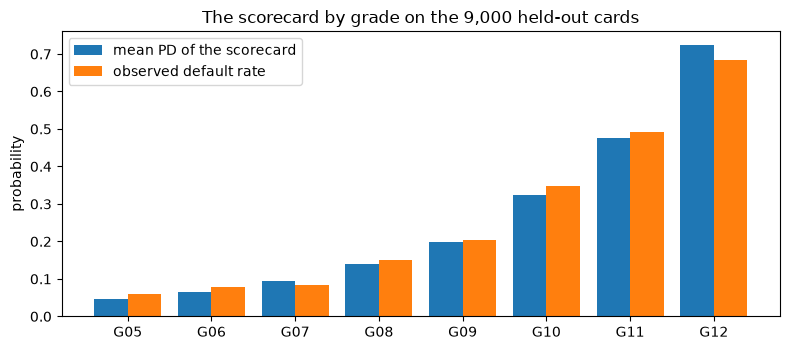

In [15]:
# Draw the mean PD and the observed default rate of each grade
fig, ax = plt.subplots(figsize=(8, 3.6))
positions = np.arange(len(grades))
ax.bar(positions - 0.2, [g["pd"] for g in grades], width=0.4, label="mean PD of the scorecard")
ax.bar(positions + 0.2, [g["dr"] for g in grades], width=0.4, label="observed default rate")
ax.set_xticks(positions)
ax.set_xticklabels([g["grade"] for g in grades])
ax.set_ylabel("probability")
ax.set_title("The scorecard by grade on the 9,000 held-out cards")
ax.legend()
fig.tight_layout()
plt.show()


## Results

- **WoE and IV are counts, nothing more.** Recomputed from the bin counts of the training slice, the WoE of every `PAY_0` bin and its IV (0.886) match the committed values to rounding error. The variable carries by far the most evidence: cards two or more months late default at about 70%, against 13% to 14% for cards that paid duly or revolved.
- **The screen is visible.** Of 20 variables, 13 reach the 0.02 threshold. `EDUCATION` falls just under it (0.0189) and the six bill amounts carry almost no evidence once the repayment status is in the model. All 13 coefficients are negative, as a sound scorecard requires.
- **The table of points is the model.** Every one of the 95 rows of the table follows from its WoE, the coefficients and the three scale numbers, and the rounded points differ from the unrounded ones by at most half a point per variable. The score of each of the 50 sample cards is exactly the sum of its 13 points.
- **Rounding costs a little.** The PD rebuilt from the integer score differs from the committed PD by up to about 0.008 on the 50 cards, because the integer points drop the decimals the model keeps. The ranking is almost untouched: the AUC of the two differs by about 0.003 on these cards (0.775 against 0.778). The PDO property holds exactly: 20 points halve the odds (the ratio is 2).
- **Ranking and grades.** The AUC on the 9,000 held-out cards is 0.759, with a narrow interval. The default rate rises from grade to grade. Only eight of the twelve grades hold cards, and the observed rate sits above the mean PD in grades G05 to G11 and below it in G12: the PDs are slightly low for most cards. That is a question for the calibration tests, and the committed rows already flag it (notebook 03 of this topic).

What this notebook does not show: how the bins and the coefficients are fitted (notebook 02), how the scorecard compares with other models (notebooks 03 and 06), or whether the fit holds up out of time (notebooks 04 and 07). The 50-card sample is too small to say anything about the scorecard's quality; the AUC interval on 50 cards is wide, as notebook 02 of topic 01 showed.

## Summary

- WoE compares the share of non-events and the share of events in a bin; IV adds the difference over the bins; both are computed from counts and recomputed here to rounding error.
- A logistic model on the WoE has negative coefficients when it is sound; the intercept and coefficients are shared out per variable into a table of points with $\mathrm{Points}_{j,b} = \mathrm{Offset}/k - (\beta_j \mathrm{WoE}_{j,b} + \beta_0/k)\,\mathrm{Factor}$.
- The scale is set by PDO, a reference score and reference odds; 20 points double the odds of being good.
- The score is the sum of the integer points, the PD can be rebuilt from it without the model, and the rounding costs a small and measurable PD gap, not a change of ranking.

**What to try next.** Read `docs/guides/03_read-a-validation-report.md` for the lights that the committed rows of this scorecard carry, then continue with notebook 02, which shows how the bins and the coefficients are fitted and why the fit must see only the training slice.

## References

- Navas-Palencia, G. (2020), Optimal binning: mathematical programming formulation, section 2.1 (WoE and IV). https://arxiv.org/abs/2001.08025
- Siddiqi, N. (2017), Intelligent Credit Scoring: Building and Implementing Better Credit Risk Scorecards, 2nd ed., Wiley. https://doi.org/10.1002/9781119282396 (the scaling formula is verified in the open implementation, ING `skorecard`, https://github.com/ing-bank/skorecard/blob/main/skorecard/rescale/rescale.py; the book page of the formula and of the 0.02 threshold is UNVERIFIED in the research.)
- Hanley, J. A. and McNeil, B. J. (1982), The meaning and use of the area under a receiver operating characteristic curve, Radiology 143(1). https://doi.org/10.1148/radiology.143.1.7063747
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, Annex 1 (section 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Yeh, I-C. (2009), Default of Credit Card Clients, UCI Machine Learning Repository (CC BY 4.0). https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients